# SPAM Tutorial: Predicting Spot-level Gene Expression from H&E Histology

**SPAM** (Spatial Profile via Adaptive Multimodal contrastive learning) recovers
spot/cell-level gene expression directly from H&E whole-slide image patches by
combining:

1. **Contrastive pretraining** — aligns an image foundation-model encoder (e.g. UNI,
   GigaPath, Virchow2, ...) with (a) gene-expression profiles and (b) the spatial
   neighborhood graph of each cell/spot.
2. **Cross-modal finetuning** — a cross-attention fusion module combines the
   pretrained image, gene and spatial-graph (GCN) embeddings and is finetuned with a
   Zero-Inflated Negative Binomial (ZINB) decoder to directly regress gene counts.
3. **Inference** — given only H&E patches (and, for the gene branch, a reference
   training profile), the finetuned model predicts the full gene-expression vector
   for every cell/spot.

This notebook walks through the expected data format, the three pipeline stages
(driven by `Code_final/code/main.py`), and how to evaluate / visualize the predicted
expression against ground truth.

> All three stages are exposed through a single unified CLI:
> ```bash
> python Code_final/code/main.py {pretrain,finetune,inference} --help
> ```


## 0. Environment setup

The project ships a conda environment spec (`Code_final/environment.yml` /
`requirements.txt`). A GPU is strongly recommended (the image foundation models
have 0.3B–1B+ parameters).

```bash
conda env create -f Code_final/environment.yml
conda activate SPAM
```

Below we just import the libraries needed for this tutorial's data-exploration and
evaluation sections (the actual training/inference stages are invoked as
command-line jobs further down).


In [1]:
import os
import numpy as np
import scipy.sparse as sp
import anndata as ad
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Root of this repository
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
print("PROJECT_ROOT:", PROJECT_ROOT)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU(s):", [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])


PROJECT_ROOT: /data/project/banana9903_xenium
CUDA available: True
GPU(s): ['NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition']


/home/banana9903/.local/lib/python3.12/site-packages/torch/cuda/__init__.py:285: UserWarning: 
    Found GPU0 NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition which is of cuda capability 12.0.
    Minimum and Maximum cuda capability supported by this version of PyTorch is
    (5.0) - (9.0)
    
  warnings.warn(
/home/banana9903/.local/lib/python3.12/site-packages/torch/cuda/__init__.py:306: UserWarning: 
    Please install PyTorch with a following CUDA
    configurations:  12.8 13.0 following instructions at
    https://pytorch.org/get-started/locally/
    
  warnings.warn(matched_cuda_warn.format(matched_arches))
/home/banana9903/.local/lib/python3.12/site-packages/torch/cuda/__init__.py:328: UserWarning: 
NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition with CUDA capability sm_120 is not compatible with the current PyTorch installation.
The current PyTorch install supports CUDA capabilities sm_50 sm_60 sm_70 sm_75 sm_80 sm_86 sm_90.
If you want to use the NVIDIA RTX PRO

## 1. Input data format

SPAM expects two inputs per tissue section:

- **`--h5ad`**: an [AnnData](https://anndata.readthedocs.io/) object where
  - `adata.X` is the (cell/spot × gene) expression matrix (log-normalized counts),
  - `adata.obs` contains at least the spatial centroid columns `x_centroid`,
    `y_centroid` (used to build the kNN spatial graph), and
  - `adata.obs_names` are the spot/cell IDs.
- **`--csv`**: a patch-mapping table linking each spot/cell ID to an H&E image patch
  on disk, with at least `spot_id` (or `cell_id`) and `patch_path` columns
  (`--root` is prepended to relative paths).

We'll use one of the example Xenium breast-cancer sections shipped with this
repository to illustrate the format.


In [2]:
DATA_DIR = "/data/project/banana9903_xenium/xenium_rep1_io/data"
PATCH_DIR = "/data/project/banana9903_xenium/xenium_rep1_io/patches_224"

adata = ad.read_h5ad(os.path.join(DATA_DIR, "merged_with_celltype_symbol_SPAM.h5ad"))
adata


AnnData object with n_obs × n_vars = 167780 × 541
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'Barcode', 'key', 'Cluster'
    var: 'highly_expressed', 'highly_variable', 'var_name_orig', 'gene_symbol', 'ensembl_id'
    uns: 'log1p'
    obsm: 'coord', 'spatial'

In [3]:
# obs metadata: spatial centroids + per-cell metadata used for evaluation/plots
adata.obs.head()


,x_centroid,y_centroid,transcript_counts,control_probe_counts,control_codeword_counts,total_counts,cell_area,nucleus_area,Barcode,key,Cluster
0,847.259912,326.191365,28,1,0,29,58.387031,26.642188,1,1,DCIS_2
1,826.341995,328.031830,94,0,0,94,197.016719,42.130781,2,2,DCIS_2
2,848.766919,331.743187,9,0,0,9,16.256250,12.688906,3,3,Unlabeled
3,824.228409,334.252643,11,0,0,11,42.311406,10.069844,4,4,Invasive_Tumor
4,841.357538,332.242505,48,0,0,48,107.652500,37.479688,5,5,DCIS_2


In [4]:
# patch mapping CSV: links each cell to a 224x224 H&E crop
patch_map = pd.read_csv(os.path.join(PATCH_DIR, "spot_patch_map_224.csv"))
patch_map[["cell_id", "x_um", "y_um", "patch_path", "inside_he"]].head()


,cell_id,x_um,y_um,patch_path,inside_he
0,1,847.259912,326.191365,./patches_224/1_x6173_y18205_224.png,True
1,2,826.341995,328.031830,./patches_224/2_x6115_y18199_224.png,True
2,3,848.766919,331.743187,./patches_224/3_x6177_y18189_224.png,True
3,4,824.228409,334.252643,./patches_224/4_x6110_y18182_224.png,True
4,5,841.357538,332.242505,./patches_224/5_x6157_y18188_224.png,True


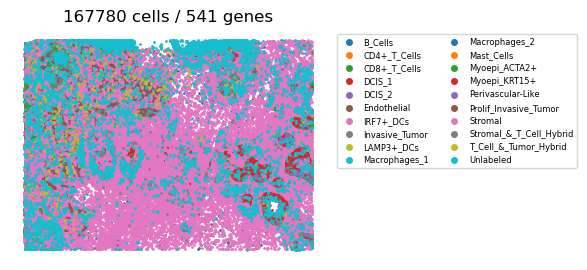

In [5]:
# Spatial layout of cells, colored by annotated cell type ("Cluster")
fig, ax = plt.subplots(figsize=(6, 6))
xy = adata.obsm["spatial"]
clusters = adata.obs["Cluster"].astype("category")
for c in clusters.cat.categories:
    m = clusters == c
    ax.scatter(xy[m, 0], -xy[m, 1], s=1, label=c)
ax.set_title(f"{adata.n_obs} cells / {adata.n_vars} genes")
ax.set_aspect("equal")
ax.axis("off")
ax.legend(markerscale=4, fontsize=6, ncol=2, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


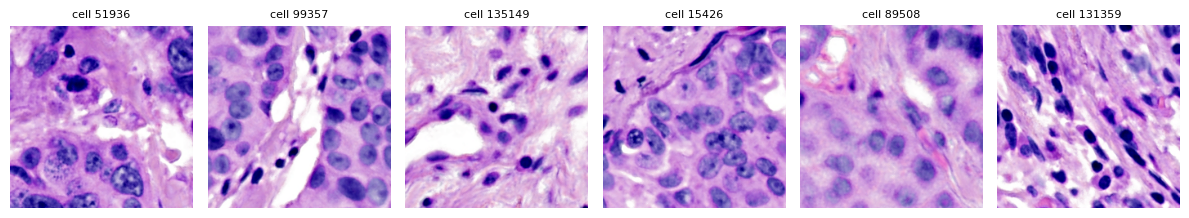

In [6]:
# A handful of example H&E patches that pair with the expression vectors above
from PIL import Image

sample = patch_map[patch_map["inside_he"]].sample(6, random_state=0)
fig, axes = plt.subplots(1, 6, figsize=(12, 2.2))
for axi, (_, row) in zip(axes, sample.iterrows()):
    img = Image.open(os.path.join(PATCH_DIR, "..", row["patch_path"]))
    axi.imshow(img)
    axi.set_title(f"cell {row['cell_id']}", fontsize=8)
    axi.axis("off")
plt.tight_layout()
plt.show()


## 2. Stage 1 — Contrastive Pretraining

`main.py pretrain` jointly trains:

- an **image encoder adapter** on top of a frozen/LoRA-tuned histology foundation
  model (`--enc_name`, e.g. `uni_v1`, `gigapath`, `virchow2`, ...),
- an **image ↔ gene** contrastive head (`SNN_pretrained.pt`),
- an **image ↔ spatial-graph** contrastive head, where the spatial graph is a kNN
  graph over `x_centroid`/`y_centroid` (`KNN_pretrained.pt`).

Outputs are written to `--save_dir` as `Image_pretrained.pt`, `SNN_pretrained.pt`
and `KNN_pretrained.pt`.

```bash
python Code_final/code/main.py pretrain \
  --h5ad /data/project/banana9903_xenium/xenium_rep1_io/data/merged_with_celltype_symbol_SPAM.h5ad \
  --csv  /data/project/banana9903_xenium/xenium_rep1_io/patches_224/spot_patch_map_224.csv \
  --root /data/project/banana9903_xenium/xenium_rep1_io \
  --enc_name uni_v1 \
  --mode joint \
  --epochs 50 --batch_size 64 --img_batch_size 256 --k 12 \
  --save_dir Code_final/code/ckpts \
  --device auto --amp
```

This is a multi-GPU-hour job on a full Xenium section, so it is **not executed by
this notebook**. A pretrained set of weights is provided under
`Code_final/code/ckpts/` (`Image_pretrained.pt`, `SNN_pretrained.pt`,
`KNN_pretrained.pt`) and is used directly in Stage 2 below.


In [7]:
RUN_TRAINING = False  # flip to True to launch the (long-running) jobs below

PRETRAIN_CMD = [
    "python", os.path.join(PROJECT_ROOT, "code", "main.py"), "pretrain",
    "--h5ad", os.path.join(DATA_DIR, "merged_with_celltype_symbol_SPAM.h5ad"),
    "--csv",  os.path.join(PATCH_DIR, "spot_patch_map_224.csv"),
    "--root", "/data/project/banana9903_xenium/xenium_rep1_io",
    "--enc_name", "uni_v1",
    "--mode", "joint",
    "--epochs", "50", "--batch_size", "64", "--img_batch_size", "256", "--k", "12",
    "--save_dir", os.path.join(PROJECT_ROOT, "code", "ckpts"),
    "--device", "auto", "--amp",
]
print(" ".join(PRETRAIN_CMD))

if RUN_TRAINING:
    import subprocess
    subprocess.run(PRETRAIN_CMD, check=True)


python /data/project/banana9903_xenium/code/main.py pretrain --h5ad /data/project/banana9903_xenium/xenium_rep1_io/data/merged_with_celltype_symbol_SPAM.h5ad --csv /data/project/banana9903_xenium/xenium_rep1_io/patches_224/spot_patch_map_224.csv --root /data/project/banana9903_xenium/xenium_rep1_io --enc_name uni_v1 --mode joint --epochs 50 --batch_size 64 --img_batch_size 256 --k 12 --save_dir /data/project/banana9903_xenium/code/ckpts --device auto --amp


## 3. Stage 2 — Cross-Attention + ZINB Finetuning

`main.py finetune` builds the full SPAM model: pretrained image encoder + gene
encoder + spatial GCN, fused via cross-attention (`--merge gated-sum` or
`concat-proj`), and decoded with a ZINB head to directly regress raw gene counts.
The Stage-1 weights are injected via `--pt_img_backbone`, `--pt_ig`, `--pt_is`.

The best checkpoint (by validation loss) is written to `<save_dir>/best/model.pt`.

```bash
python Code_final/code/main.py finetune \
  --h5ad /data/project/banana9903_xenium/xenium_rep1_io/data/merged_with_celltype_symbol_SPAM.h5ad \
  --csv  /data/project/banana9903_xenium/xenium_rep1_io/patches_224/spot_patch_map_224.csv \
  --root /data/project/banana9903_xenium/xenium_rep1_io \
  --enc_name uni_v1 \
  --epochs 20 --batch_size 128 --k 12 --lr 3e-4 --weight_decay 0.05 \
  --merge gated-sum --proj_dim_gene 256 --proj_dim_spot 256 --fuse_dim 512 --heads 8 \
  --device auto --amp --save_dir Code_final/ckpts_cross \
  --pt_img_backbone Code_final/code/ckpts/Image_pretrained.pt \
  --pt_ig           Code_final/code/ckpts/SNN_pretrained.pt \
  --pt_is           Code_final/code/ckpts/KNN_pretrained.pt
```

Again, this is a long-running GPU job and is not executed here. A finetuned
checkpoint is provided at `Code_final/ckpts_cross/best/model.pt`.


In [8]:
FINETUNE_CMD = [
    "python", os.path.join(PROJECT_ROOT, "code", "main.py"), "finetune",
    "--h5ad", os.path.join(DATA_DIR, "merged_with_celltype_symbol_SPAM.h5ad"),
    "--csv",  os.path.join(PATCH_DIR, "spot_patch_map_224.csv"),
    "--root", "/data/project/banana9903_xenium/xenium_rep1_io",
    "--enc_name", "uni_v1",
    "--epochs", "20", "--batch_size", "128", "--k", "12",
    "--lr", "3e-4", "--weight_decay", "0.05",
    "--merge", "gated-sum",
    "--proj_dim_gene", "256", "--proj_dim_spot", "256", "--fuse_dim", "512", "--heads", "8",
    "--device", "auto", "--amp",
    "--save_dir", os.path.join(PROJECT_ROOT, "ckpts_cross"),
    "--pt_img_backbone", os.path.join(PROJECT_ROOT, "code", "ckpts", "Image_pretrained.pt"),
    "--pt_ig",           os.path.join(PROJECT_ROOT, "code", "ckpts", "SNN_pretrained.pt"),
    "--pt_is",           os.path.join(PROJECT_ROOT, "code", "ckpts", "KNN_pretrained.pt"),
]
print(" ".join(FINETUNE_CMD))

if RUN_TRAINING:
    import subprocess
    subprocess.run(FINETUNE_CMD, check=True)


python /data/project/banana9903_xenium/code/main.py finetune --h5ad /data/project/banana9903_xenium/xenium_rep1_io/data/merged_with_celltype_symbol_SPAM.h5ad --csv /data/project/banana9903_xenium/xenium_rep1_io/patches_224/spot_patch_map_224.csv --root /data/project/banana9903_xenium/xenium_rep1_io --enc_name uni_v1 --epochs 20 --batch_size 128 --k 12 --lr 3e-4 --weight_decay 0.05 --merge gated-sum --proj_dim_gene 256 --proj_dim_spot 256 --fuse_dim 512 --heads 8 --device auto --amp --save_dir /data/project/banana9903_xenium/ckpts_cross --pt_img_backbone /data/project/banana9903_xenium/code/ckpts/Image_pretrained.pt --pt_ig /data/project/banana9903_xenium/code/ckpts/SNN_pretrained.pt --pt_is /data/project/banana9903_xenium/code/ckpts/KNN_pretrained.pt


## 4. Stage 3 — Inference

`main.py inference` predicts gene expression for a (held-out) section using only its
H&E patches. The gene branch is fed a reference profile derived from `--train_h5ad`
(gene-wise mean of the training section), the image branch runs through the
finetuned encoder, and the cross-attention + ZINB head produces the predicted
expression matrix, written to `--out_h5ad`.

```bash
python Code_final/code/main.py inference \
  --h5ad       /path/to/held_out_section.h5ad \
  --csv        /path/to/held_out_patch_map.csv \
  --root       /path/to/held_out_root \
  --train_h5ad /data/project/banana9903_xenium/xenium_rep1_io/data/merged_with_celltype_symbol_SPAM.h5ad \
  --enc_name uni_v1 \
  --proj_dim_gene 256 --proj_dim_spot 256 --fuse_dim 512 --heads 8 --k 12 \
  --device auto --amp \
  --ft_model_ckpt   Code_final/ckpts_cross/best/model.pt \
  --pt_img_backbone Code_final/code/ckpts/Image_pretrained.pt \
  --pt_ig           Code_final/code/ckpts/SNN_pretrained.pt \
  --pt_is           Code_final/code/ckpts/KNN_pretrained.pt \
  --out_h5ad ./inference/recovered_eval.h5ad
```

The output `--out_h5ad` has the **same `obs_names`/`obsm['spatial']`** as the input
`--h5ad`, with `adata.X` replaced by the predicted expression matrix (same
`var_names`/gene order as `--train_h5ad`) — ready to compare directly against
ground truth, as we do in the next section.


In [9]:
INFERENCE_CMD = [
    "python", os.path.join(PROJECT_ROOT, "code", "main.py"), "inference",
    "--h5ad",       os.path.join(DATA_DIR, "merged_with_celltype_symbol_SPAM.h5ad"),
    "--csv",        os.path.join(PATCH_DIR, "spot_patch_map_224.csv"),
    "--root",       "/data/project/banana9903_xenium/xenium_rep1_io",
    "--train_h5ad", os.path.join(DATA_DIR, "merged_with_celltype_symbol_SPAM.h5ad"),
    "--enc_name", "uni_v1",
    "--proj_dim_gene", "256", "--proj_dim_spot", "256", "--fuse_dim", "512", "--heads", "8", "--k", "12",
    "--device", "auto", "--amp",
    "--ft_model_ckpt",   os.path.join(PROJECT_ROOT, "ckpts_cross", "best", "model.pt"),
    "--pt_img_backbone", os.path.join(PROJECT_ROOT, "code", "ckpts", "Image_pretrained.pt"),
    "--pt_ig",           os.path.join(PROJECT_ROOT, "code", "ckpts", "SNN_pretrained.pt"),
    "--pt_is",           os.path.join(PROJECT_ROOT, "code", "ckpts", "KNN_pretrained.pt"),
    "--out_h5ad", "/data/project/banana9903_xenium/inference/recovered_eval.h5ad",
]
print(" ".join(INFERENCE_CMD))

if RUN_TRAINING:
    import subprocess
    subprocess.run(INFERENCE_CMD, check=True)


python /data/project/banana9903_xenium/code/main.py inference --h5ad /data/project/banana9903_xenium/xenium_rep1_io/data/merged_with_celltype_symbol_SPAM.h5ad --csv /data/project/banana9903_xenium/xenium_rep1_io/patches_224/spot_patch_map_224.csv --root /data/project/banana9903_xenium/xenium_rep1_io --train_h5ad /data/project/banana9903_xenium/xenium_rep1_io/data/merged_with_celltype_symbol_SPAM.h5ad --enc_name uni_v1 --proj_dim_gene 256 --proj_dim_spot 256 --fuse_dim 512 --heads 8 --k 12 --device auto --amp --ft_model_ckpt /data/project/banana9903_xenium/ckpts_cross/best/model.pt --pt_img_backbone /data/project/banana9903_xenium/code/ckpts/Image_pretrained.pt --pt_ig /data/project/banana9903_xenium/code/ckpts/SNN_pretrained.pt --pt_is /data/project/banana9903_xenium/code/ckpts/KNN_pretrained.pt --out_h5ad /data/project/banana9903_xenium/inference/recovered_eval.h5ad


## 5. Evaluating predictions

To illustrate the expected output and a typical evaluation, we load a previously
generated prediction (`inference/recovered_breast_xattn.h5ad`) for this breast
section and compare it gene-by-gene against the ground-truth expression matrix
using the Pearson correlation coefficient (PCC).


In [10]:
INFER_DIR = "/data/project/banana9903_xenium/inference"

gt = adata  # ground-truth expression loaded in Section 1
pred = ad.read_h5ad(os.path.join(INFER_DIR, "recovered_breast_xattn.h5ad"))

assert (gt.obs_names == pred.obs_names).all()
# pred.var_names are anonymized placeholders ("Gene0", "Gene1", ...) but are in the
# same order as gt.var_names
assert gt.n_vars == pred.n_vars

gtX = gt.X.toarray() if sp.issparse(gt.X) else np.asarray(gt.X)
predX = np.asarray(pred.X)
print("ground truth:", gtX.shape, " predicted:", predX.shape)


ground truth: (167780, 541)  predicted: (167780, 541)


In [11]:
def pearson_per_gene(a, b):
    a = a - a.mean(0, keepdims=True)
    b = b - b.mean(0, keepdims=True)
    num = (a * b).sum(0)
    den = np.sqrt((a ** 2).sum(0) * (b ** 2).sum(0)) + 1e-9
    return num / den

pcc = pearson_per_gene(gtX, predX)
pcc_df = pd.Series(pcc, index=gt.var_names, name="pcc").sort_values(ascending=False)

print(f"Mean PCC over {len(pcc_df)} genes: {pcc_df.mean():.3f}")
print(f"Median PCC: {pcc_df.median():.3f}")
pcc_df.head(10)


Mean PCC over 541 genes: 0.240
Median PCC: 0.197


EPCAM      0.759425
KRT7       0.752541
PTPRC      0.744869
CD3E       0.726979
FOXA1      0.717153
KRT8       0.712524
CLEC14A    0.711118
TACSTD2    0.703406
KRT5       0.702443
KRT14      0.690239
Name: pcc, dtype: float64

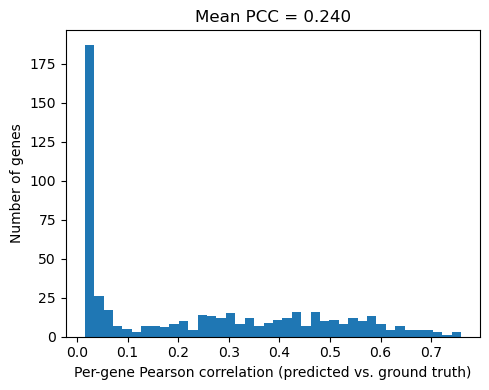

In [12]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.hist(pcc_df.values, bins=40)
ax.set_xlabel("Per-gene Pearson correlation (predicted vs. ground truth)")
ax.set_ylabel("Number of genes")
ax.set_title(f"Mean PCC = {pcc_df.mean():.3f}")
plt.tight_layout()
plt.show()


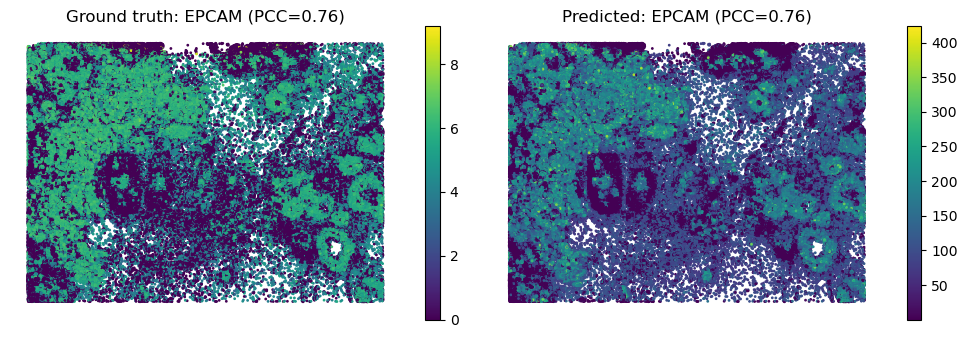

In [13]:
# Spatial expression map for one of the best-recovered genes
gene = pcc_df.index[0]
gi = gt.var_names.get_loc(gene)
xy = gt.obsm["spatial"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for axi, (vals, title) in zip(axes, [(gtX[:, gi], "Ground truth"), (predX[:, gi], "Predicted")]):
    sca = axi.scatter(xy[:, 0], -xy[:, 1], c=vals, s=1, cmap="viridis")
    axi.set_title(f"{title}: {gene} (PCC={pcc_df[gene]:.2f})")
    axi.set_aspect("equal")
    axi.axis("off")
    plt.colorbar(sca, ax=axi, shrink=0.7)
plt.tight_layout()
plt.show()


## Summary

| Stage | Script (via `main.py`) | Inputs | Outputs |
|---|---|---|---|
| 1. Pretraining | `pretrain` → `code/utils/run_contrastive.py` | h5ad, patch CSV | `Image_pretrained.pt`, `SNN_pretrained.pt`, `KNN_pretrained.pt` |
| 2. Finetuning  | `finetune` → `code/utils/run_finetuning.py` | h5ad, patch CSV, Stage-1 weights | `best/model.pt` |
| 3. Inference   | `inference` → `code/utils/run_inference.py` | held-out h5ad/CSV, Stage-2 weights, train h5ad | predicted expression `.h5ad` |

The predicted `.h5ad` shares `obs_names`/`obsm['spatial']`/`var_names` with the
input, so it can be dropped directly into downstream analyses (clustering,
differential expression, spatial visualization, etc.) alongside or in place of the
measured Xenium data.
